Numero di sequenze: 19388
Lunghezze presenti: Counter({566: 19388})


,position,entropy_bits,n_distinct,most_common_aa,most_common_frequency
0,1,-0.000000,1,M,1.000000
1,2,0.030403,6,K,0.997318
2,3,0.023557,7,T,0.998092
3,4,0.056756,5,I,0.994481
4,5,0.010134,6,I,0.999278
5,6,0.003839,4,A,0.999742
6,7,0.030600,7,L,0.997370
7,8,0.045480,8,S,0.995719
8,9,0.167691,9,Y,0.979369
9,10,0.051748,8,I,0.995461


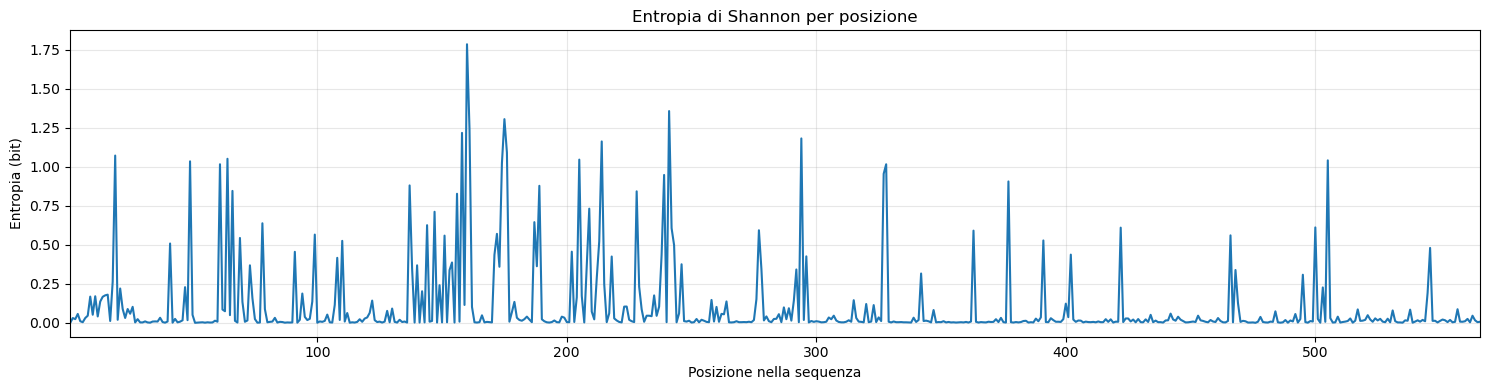

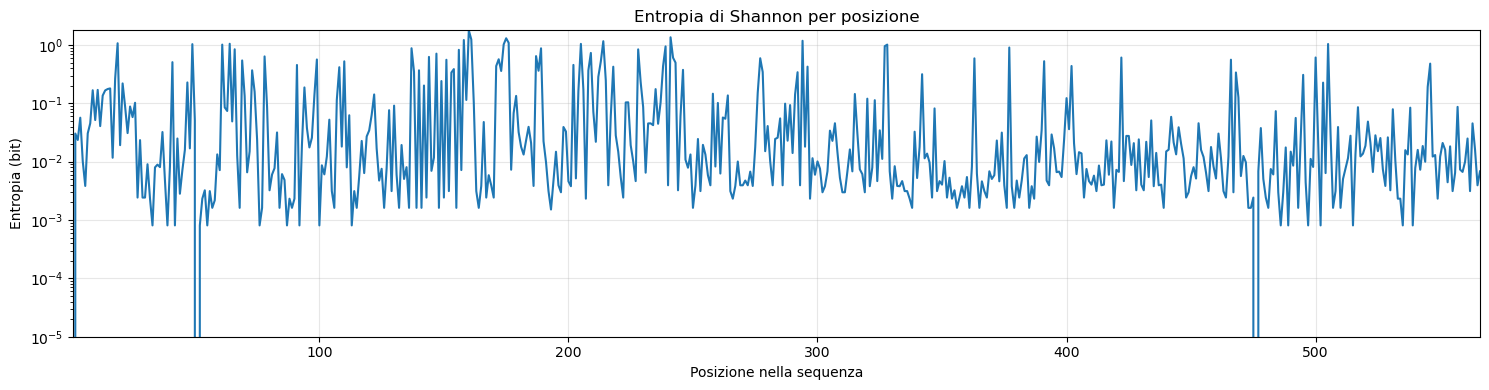

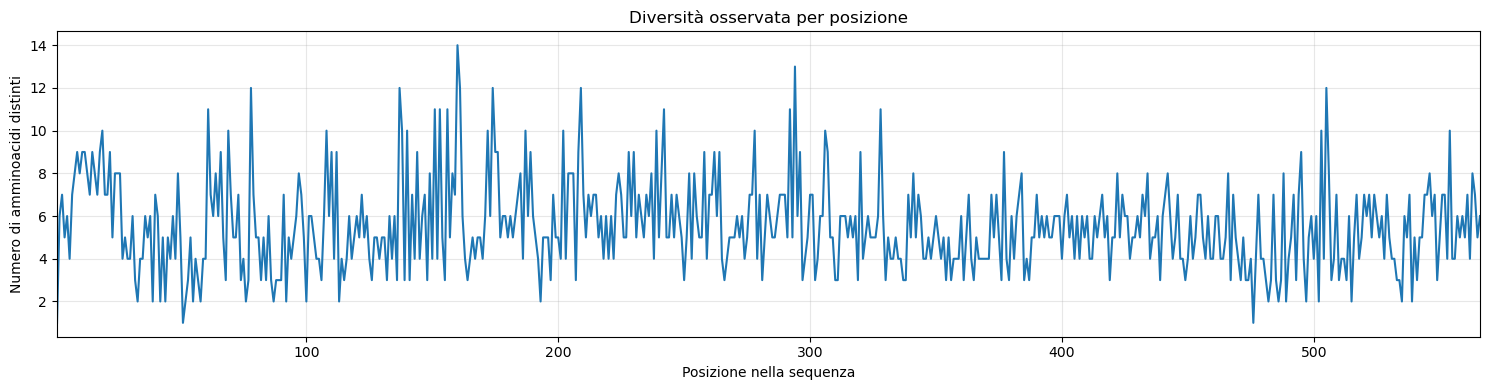

Entropia media: 0.1061 bit
Entropia minima: -0.0000 bit
Entropia massima osservata: 1.7845 bit
Numero massimo di simboli distinti in un sito: 14
Risultati salvati in site_entropy_566.csv


In [9]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path

# 1. Leggi il file FASTA
fasta_path = Path("sequences_H3N2_566_homo_segment4.fasta")

sequences = []
current_sequence = []

with open(fasta_path, "r") as f:
    for line in f:
        line = line.strip()

        if not line:
            continue

        if line.startswith(">"):
            if current_sequence:
                sequences.append("".join(current_sequence))
                current_sequence = []
        else:
            current_sequence.append(line.upper())

    if current_sequence:
        sequences.append("".join(current_sequence))

print(f"Numero di sequenze: {len(sequences)}")

# 2. Controlla le lunghezze
lengths = [len(seq) for seq in sequences]
print("Lunghezze presenti:", Counter(lengths))

if len(set(lengths)) != 1:
    raise ValueError("Le sequenze non hanno tutte la stessa lunghezza.")

L = lengths[0]
N = len(sequences)

if L != 566:
    raise ValueError(f"Attese sequenze di 566 aa, trovate di lunghezza {L}.")

# Matrice: righe = sequenze, colonne = posizioni
X = np.array([list(seq) for seq in sequences])

# 3. Calcola entropia e numero di amminoacidi distinti
entropy = np.zeros(L)
n_distinct = np.zeros(L, dtype=int)
most_common = []
max_frequency = np.zeros(L)

for i in range(L):
    counts = Counter(X[:, i])
    frequencies = np.array(list(counts.values()), dtype=float) / N

    # Entropia di Shannon in bit
    entropy[i] = -np.sum(frequencies * np.log2(frequencies))

    # Numero di simboli distinti osservati
    n_distinct[i] = len(counts)

    # Amminoacido più frequente e sua frequenza
    aa, count = counts.most_common(1)[0]
    most_common.append(aa)
    max_frequency[i] = count / N

# 4. Crea una tabella dei risultati
results = pd.DataFrame({
    "position": np.arange(1, L + 1),
    "entropy_bits": entropy,
    "n_distinct": n_distinct,
    "most_common_aa": most_common,
    "most_common_frequency": max_frequency
})

display(results.head(10))

# 5. Grafico dell'entropia sito per sito
plt.figure(figsize=(15, 4))
plt.plot(results["position"], results["entropy_bits"])
plt.xlabel("Posizione nella sequenza")
plt.ylabel("Entropia (bit)")
plt.title("Entropia di Shannon per posizione")
plt.xlim(1, L)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Grafico dell'entropia sito per sito in scala logaritmica
plt.figure(figsize=(15, 4))
plt.plot(results["position"], results["entropy_bits"])
plt.xlabel("Posizione nella sequenza")
plt.ylabel("Entropia (bit)")
plt.title("Entropia di Shannon per posizione")
#y axis in log scale
plt.yscale("log")
plt.xlim(1, L)
#lower limit of y axis to minimum entropy value
plt.ylim(0.00001, entropy.max())
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Grafico del numero di amminoacidi distinti per posizione
plt.figure(figsize=(15, 4))
plt.plot(results["position"], results["n_distinct"])
plt.xlabel("Posizione nella sequenza")
plt.ylabel("Numero di amminoacidi distinti")
plt.title("Diversità osservata per posizione")
plt.xlim(1, L)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Salva i risultati
results.to_csv("site_entropy_566.csv", index=False)

print(f"Entropia media: {entropy.mean():.4f} bit")
print(f"Entropia minima: {entropy.min():.4f} bit")
print(f"Entropia massima osservata: {entropy.max():.4f} bit")
print(f"Numero massimo di simboli distinti in un sito: {n_distinct.max()}")
print("Risultati salvati in site_entropy_566.csv")
